# Adversarial Search: Playing Connect 4

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [ ]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

### Định nghĩa bài toán tìm kiếm cho Connect 4

* **Trạng thái ban đầu (Initial State - $S_0$):** Một bàn cờ trống kích thước $R \times C$ (kích thước chuẩn là $6 \times 7$), được biểu diễn dưới dạng mảng NumPy 2D số nguyên chứa toàn giá trị `0`. Người chơi 1 (Đỏ, ký hiệu là `1`) đi trước, người chơi 2 (Vàng, ký hiệu là `-1`) đi sau.
* **Tập hành động hợp lệ ($\text{Actions}(s)$):** Tại trạng thái $s$, tập các hành động hợp lệ bao gồm tất cả chỉ số cột $c \in \{0, 1, \dots, C-1\}$ chưa bị đầy — tức là ô trên cùng của cột $c$ vẫn còn trống ($s[0, c] == 0$).
* **Mô hình chuyển trạng thái ($\text{Result}(s, p, a)$):** Trả về trạng thái bàn cờ mới $s'$ sau khi người chơi $p \in \{1, -1\}$ thả một quân cờ vào cột $a$. Do tác dụng của trọng lực, quân cờ sẽ rơi xuống hàng trống thấp nhất $r$ (chỉ số hàng lớn nhất) trong cột $a$ thỏa mãn $s[r, a] == 0$. Hàm tạo một bản sao của $s$ để không làm thay đổi trạng thái gốc.
* **Trạng thái kết thúc ($\text{Terminal}(s)$):** Trạng thái $s$ là trạng thái kết thúc (`True`) nếu một trong hai người chơi nối được 4 quân liên tiếp cùng màu theo hàng ngang, cột dọc, hoặc đường chéo, hoặc khi toàn bộ bàn cờ đã đầy (không còn nước đi hợp lệ). Ngược lại, hàm trả về `False`.
* **Hàm lợi ích ($\text{Utility}(s, p)$):** Đánh giá điểm số của trạng thái kết thúc $s$ theo góc nhìn của người chơi $p$:
  * $+1$ nếu người chơi $p$ thắng.
  * $-1$ nếu đối thủ ($-p$) thắng.
  * $0$ nếu ván đấu hòa.
  * `None` nếu $s$ chưa phải là trạng thái kết thúc.

How big is the state space? Give an estimate and explain it.

### Ước lượng kích thước không gian trạng thái (State Space)

1. **Cận trên thô ($3^{42}$):**
   Bàn cờ Connect 4 tiêu chuẩn có kích thước $6 \times 7 = 42$ ô, mỗi ô có thể nhận 1 trong 3 giá trị (`0` là ô trống, `1` là quân người chơi 1, `-1` là quân người chơi -1). Nếu bỏ qua mọi luật chơi, số cấu hình tối đa là:
   $$3^{42} \approx 1.09 \times 10^{20} \text{ cấu hình.}$$

2. **Cận trên xét theo ràng buộc trọng lực ($127^7$):**
   Do quân cờ luôn rơi xuống vị trí trống thấp nhất trong cột, một cột cao 6 ô chỉ có thể chứa $k \in \{0, 1, \dots, 6\}$ quân xếp liên tục từ đáy lên, với $2^k$ cách gán màu cho $k$ quân đó. Do vậy, số cấu hình hợp lệ của một cột đơn lẻ là:
   $$\sum_{k=0}^{6} 2^k = 1 + 2 + 4 + 8 + 16 + 32 + 64 = 127$$
   Với 7 cột độc lập, số trạng thái bàn cờ thỏa mãn quy tắc trọng lực là:
   $$127^7 \approx 5.33 \times 10^{14} \text{ trạng thái.}$$

3. **Không gian trạng thái hợp lệ thực tế ($\approx 4.53 \times 10^{12}$):**
   Khi loại bỏ thêm các cấu hình vi phạm luật luân phiên lượt đi (số quân `1` phải bằng hoặc nhiều hơn số quân `-1` tối đa 1 quân) và các trạng thái không thể xảy ra do ván đấu dừng ngay lập tức khi có người nối đủ 4 quân, số trạng thái hợp lệ thực tế (đã được John Tromp chứng minh chính xác) là:
   $$\mathbf{4,531,985,219,092 \approx 4.53 \times 10^{12}} \text{ trạng thái.}$$

How big is the game tree that minimax search will go through? Give an estimate and explain it.

### Ước lượng kích thước cây trò chơi (Game Tree)

1. **Cận trên lý thuyết ($b^d = 7^{42}$):**
   * **Hệ số phân nhánh ($b$):** Ở mỗi lượt, người chơi có tối đa $b = 7$ cột để thả quân.
   * **Độ sâu tối đa ($d$):** Một ván đấu kéo dài tối đa $d = 42$ nước đi (ply) trước khi bàn cờ đầy kín.
   * Do đó, cận trên lý thuyết của số nút lá trong cây trò chơi là:
     $$b^d = 7^{42} \approx 3.12 \times 10^{35} \text{ nhánh.}$$

2. **Ước lượng cây trò chơi thực tế ($\approx 10^{21} \text{ đến } 10^{25}$ nút):**
   * Trong thực tế, các cột sẽ đầy dần trong quá trình chơi, làm hệ số phân nhánh trung bình giảm xuống còn $b_{\text{eff}} \approx 4\text{--}5$.
   * Ngoài ra, phần lớn các ván đấu phân định thắng thua trước khi lấp đầy cả 42 ô (độ sâu trung bình $d_{\text{avg}} \approx 36$ nước đi).
   * Vì vậy, tổng số nút thực tế mà cây trò chơi chứa vào khoảng:
     $$4^{36} \text{ đến } 5^{36} \approx \mathbf{10^{21} \text{ đến } 10^{25}} \text{ nút.}$$

3. **Kết luận:**
   Do nhiều trình tự nước đi khác nhau (hoán vị nước đi - transpositions) có thể dẫn đến cùng một trạng thái bàn cờ, kích thước cây trò chơi ($\sim 10^{21}\text{--}10^{35}$) lớn hơn gấp nhiều lần so với không gian trạng thái ($\sim 4.53 \times 10^{12}$), khiến việc duyệt vét cạn toàn bộ cây bằng Minimax là bất khả thi trên bàn cờ $6 \times 7$.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [ ]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

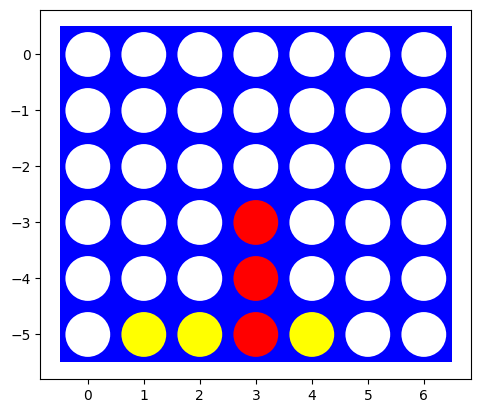

In [ ]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()

board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [ ]:
import numpy as np

def empty_board(shape=(6, 7)):
    """Initial state: Tạo bàn cờ trống kích thước (rows, cols)."""
    return np.zeros(shape, dtype=int)

def actions(state):
    """Actions(s): Trả về danh sách chỉ số các cột hợp lệ (ô trên cùng còn trống)."""
    return [col for col in range(state.shape[1]) if state[0, col] == 0]

def result(state, player, action):
    """Transition model Result(s, p, a): Thả quân của người chơi `player` vào cột `action`."""
    if state[0, action] != 0:
        raise ValueError(f"Hành động không hợp lệ {action}: Cột đã đầy!")

    new_state = state.copy()
    # Tìm hàng trống thấp nhất (chỉ số lớn nhất) trong cột được chọn
    empty_rows = np.where(new_state[:, action] == 0)[0]
    row = empty_rows[-1]
    new_state[row, action] = player
    return new_state

def check_winner(state):
    """
    Hàm phụ trợ: Kiểm tra trạng thái thắng/thua/hòa của bàn cờ.
    Trả về:
        1  : Người chơi 1 thắng
       -1  : Người chơi -1 thắng
        0  : Hòa (bàn cờ đã đầy)
       None: Trò chơi vẫn đang tiếp diễn
    """
    rows, cols = state.shape

    # 1. Kiểm tra hàng ngang
    for r in range(rows):
        for c in range(cols - 3):
            window = state[r, c:c+4]
            if window[0] != 0 and np.all(window == window[0]):
                return int(window[0])

    # 2. Kiểm tra cột dọc
    for r in range(rows - 3):
        for c in range(cols):
            window = state[r:r+4, c]
            if window[0] != 0 and np.all(window == window[0]):
                return int(window[0])

    # 3. Kiểm tra đường chéo chính (\)
    for r in range(rows - 3):
        for c in range(cols - 3):
            if (state[r, c] != 0 and
                state[r, c] == state[r+1, c+1] == state[r+2, c+2] == state[r+3, c+3]):
                return int(state[r, c])

    # 4. Kiểm tra đường chéo phụ (/)
    for r in range(3, rows):
        for c in range(cols - 3):
            if (state[r, c] != 0 and
                state[r, c] == state[r-1, c+1] == state[r-2, c+2] == state[r-3, c+3]):
                return int(state[r, c])

    # 5. Kiểm tra hòa (hàng trên cùng đã lấp đầy)
    if np.all(state[0, :] != 0):
        return 0

    return None

def terminal(state):
    """Terminal(s): Trả về True nếu trò chơi đã kết thúc, ngược lại trả về False."""
    return check_winner(state) is not None

def utility(state, player=1):
    """Utility(s, p): Trả về +1 nếu thắng, -1 nếu thua, 0 nếu hòa, None nếu chưa kết thúc."""
    winner = check_winner(state)
    if winner is None:
        return None
    if winner == 0:
        return 0
    return 1 if winner == player else -1

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [ ]:
# Your code/ answer goes here.

def random_player(board, player=1):
    """
    Tác tử chọn ngẫu nhiên một nước đi hợp lệ (xác suất đều trên tất cả các cột chưa đầy).
    Tham số `player` được giữ đúng chuẩn giao diện (signature) của toàn bộ hệ thống.
    """
    valid_moves = actions(board)
    return int(np.random.choice(valid_moves))

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [ ]:
def play(player1, player2, N=1000, shape=(6, 7), max_turns=200, show_final_board=False):
    """
    Cho hai tác tử thi đấu với nhau N ván trên bàn cờ kích thước `shape`.
    - player1 cầm quân 1 (Đỏ) đi trước.
    - player2 cầm quân -1 (Vàng) đi sau.
    - Tuân thủ giới hạn max_turns = 200 (vượt quá xử Hòa).
    """
    results = {1: 0, -1: 0, 0: 0}  # 1: Player 1 thắng, -1: Player -1 thắng, 0: Hòa

    for _ in range(N):
        board = empty_board(shape)
        turns = 0

        while True:
            # Lượt của Player 1 (cầm quân 1)
            move1 = player1(board, 1)
            board = result(board, 1, move1)
            turns += 1

            winner = check_winner(board)
            if winner is not None:
                results[winner] += 1
                break
            if turns >= max_turns:
                results[0] += 1
                break

            # Lượt của Player 2 (cầm quân -1)
            move2 = player2(board, -1)
            board = result(board, -1, move2)
            turns += 1

            winner = check_winner(board)
            if winner is not None:
                results[winner] += 1
                break
            if turns >= max_turns:
                results[0] += 1
                break

        if show_final_board:
            visualize(board)

    return results

# Cố định seed để kết quả tái lập được và chạy 1.000 ván đấu
np.random.seed(42)
N_games = 1000
res_random = play(random_player, random_player, N=N_games, shape=(6, 7), max_turns=200)

print(f"Kết quả sau {N_games} ván giữa 2 Random Agent (bàn 6x7):")
print(f"  - Người chơi 1 (Đi trước - Đỏ) thắng : {res_random[1]} ván ({res_random[1]/N_games*100:.1f}%)")
print(f"  - Người chơi -1 (Đi sau - Vàng) thắng: {res_random[-1]} ván ({res_random[-1]/N_games*100:.1f}%)")
print(f"  - Hòa (Draw)                         : {res_random[0]} ván ({res_random[0]/N_games*100:.1f}%)")

Kết quả sau 1000 ván giữa 2 Random Agent (bàn 6x7):
  - Người chơi 1 (Đi trước - Đỏ) thắng : 532 ván (53.2%)
  - Người chơi -1 (Đi sau - Vàng) thắng: 468 ván (46.8%)
  - Hòa (Draw)                         : 0 ván (0.0%)


### Nhận xét kết quả thực nghiệm (1.000 ván Random vs Random)

1. **Kết quả thực nghiệm ghi nhận được:**
   * **Người chơi 1 (đi trước - Đỏ):** Thắng **532 ván (53.2%)**.
   * **Người chơi -1 (đi sau - Vàng):** Thắng **468 ván (46.8%)**.
   * **Hòa (Draw):** **0 ván (0.0%)**.

2. **Giải thích tính hợp lý của kết quả:**
   * **Lợi thế đi trước (First-player advantage):** Kết quả này hoàn toàn đúng với kỳ vọng lý thuyết. Trong Connect 4, người đi trước luôn có lợi thế chủ động tạo các chuỗi đe dọa 4 quân trước và luôn sở hữu nhiều hơn đối thủ tối đa 1 quân trên bàn cờ ở các lượt lẻ. Ngay cả khi cả hai tác tử đều chọn nước đi ngẫu nhiên đồng đều, lợi thế đi trước vẫn giúp Người chơi 1 đạt tỷ lệ thắng cao hơn **6.4%** (532 so với 468 ván) so với Người chơi -1.
   * **Tỷ lệ hòa bằng 0%:** Khác với Tic-Tac-Toe 3×3 (nơi việc đánh ngẫu nhiên vẫn dễ dẫn tới hòa do không gian hẹp), bàn cờ Connect 4 có tới 6×7 = 42 ô và rất nhiều hướng nối 4 quân (ngang, dọc, hai đường chéo). Xác suất để 42 quân cờ lấp đầy ngẫu nhiên mà không vô tình tạo thành bất kỳ bộ 4 liên tiếp nào là cực kỳ nhỏ, dẫn tới 100% ván đấu đều phân định được thắng thua.

## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points]

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [ ]:
import time

class MinimaxAgent:
    """
    Tác tử Minimax tích hợp cắt tỉa Alpha-Beta.
    Sử dụng class để lưu trữ trạng thái nội bộ (số nút đã duyệt, thời gian suy nghĩ, chiến lược sắp xếp nước đi)
    theo đúng mẫu của store_agent_state_information.ipynb, đồng thời giữ đúng signature act(board, player=1).
    """
    def __init__(self, name="Minimax Alpha-Beta", use_move_ordering=True):
        self.name = name
        self.use_move_ordering = use_move_ordering
        self.nodes_explored = 0       # Lưu số nút đã duyệt ở nước đi gần nhất
        self.total_nodes = 0          # Tổng số nút đã duyệt qua nhiều lượt
        self.last_move_time = 0.0     # Thời gian (ms) của nước đi gần nhất
        self.total_time_ms = 0.0      # Tổng thời gian suy nghĩ (ms)
        self.move_count = 0           # Tổng số nước đã đi

    def _order_actions(self, valid_actions, num_cols):
        """Sắp xếp thứ tự duyệt các cột: ưu tiên cột ở giữa bàn cờ trước."""
        if not self.use_move_ordering:
            return valid_actions
        center = (num_cols - 1) / 2.0
        return sorted(valid_actions, key=lambda col: abs(col - center))

    def _max_value(self, state, alpha, beta, player):
        self.nodes_explored += 1
        win = check_winner(state)
        if win is not None:
            if win == 0:
                return 0, None
            return (1 if win == player else -1), None

        v = -float('inf')
        best_action = None
        ordered_moves = self._order_actions(actions(state), state.shape[1])

        for a in ordered_moves:
            next_state = result(state, player, a)
            v2, _ = self._min_value(next_state, alpha, beta, player)
            if v2 > v:
                v = v2
                best_action = a
                alpha = max(alpha, v)
            if v >= beta:
                return v, best_action
        return v, best_action

    def _min_value(self, state, alpha, beta, player):
        self.nodes_explored += 1
        win = check_winner(state)
        if win is not None:
            if win == 0:
                return 0, None
            return (1 if win == player else -1), None

        v = float('inf')
        best_action = None
        opponent = -player
        ordered_moves = self._order_actions(actions(state), state.shape[1])

        for a in ordered_moves:
            next_state = result(state, opponent, a)
            v2, _ = self._max_value(next_state, alpha, beta, player)
            if v2 < v:
                v = v2
                best_action = a
                beta = min(beta, v)
            if v <= alpha:
                return v, best_action
        return v, best_action

    def act(self, board, player=1):
        """Chọn nước đi tối ưu cho `player` trên bàn cờ `board`."""
        self.nodes_explored = 0
        t0 = time.perf_counter()

        _, best_action = self._max_value(board, -float('inf'), float('inf'), player)

        elapsed_ms = (time.perf_counter() - t0) * 1000.0
        self.last_move_time = elapsed_ms
        self.total_time_ms += elapsed_ms
        self.total_nodes += self.nodes_explored
        self.move_count += 1
        return int(best_action)

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [ ]:
# Your code/ answer goes here.

# Tạo 5 bàn cờ 4x4 thủ công để kiểm tra khả năng nhận diện cơ hội thắng/chặn của Minimax
test_boards_4x4 = []

# Bàn 1: Player 1 có 3 quân ngang ở hàng đáy (cột 0,1,2) -> Phải đánh cột 3 để thắng ngay
b1 = np.array([
    [ 0,  0,  0, 0],
    [ 0,  0,  0, 0],
    [-1, -1, -1, 0],
    [ 1,  1,  1, 0]
])
test_boards_4x4.append(("Bàn 1 (Thắng ngang cột 3)", b1, 3))

# Bàn 2: Player 1 có 3 quân dọc ở cột 1 -> Phải đánh cột 1 để thắng ngay
b2 = np.array([
    [ 0,  0,  0,  0],
    [ 0,  1,  0,  0],
    [-1,  1, -1,  0],
    [-1,  1,  0,  0]
])
test_boards_4x4.append(("Bàn 2 (Thắng dọc cột 1)", b2, 1))

# Bàn 3: Đối thủ (-1) sắp thắng ngang ở hàng đáy (cột 1,2,3) -> Player 1 phải chặn cột 0
b3 = np.array([
    [ 0,  0,  0,  0],
    [ 0,  0,  0,  0],
    [ 0,  1,  1,  0],
    [ 0, -1, -1, -1]
])
test_boards_4x4.append(("Bàn 3 (Chặn đối thủ thắng ngang cột 0)", b3, 0))

# Bàn 4: Player 1 sắp thắng đường chéo (/) ở cột 3
b4 = np.array([
    [ 0,  0,  0,  0],
    [ 0,  0,  1, -1],
    [ 0,  1, -1,  1],
    [ 1, -1,  1, -1]
])
test_boards_4x4.append(("Bàn 4 (Thắng chéo cột 3)", b4, 3))

# Bàn 5: Bàn cờ trung cuộc sắp đầy (còn 4 ô trống)
b5 = np.array([
    [ 0,  0,  0,  0],
    [ 1, -1,  1, -1],
    [-1,  1, -1,  1],
    [ 1, -1,  1, -1]
])
test_boards_4x4.append(("Bàn 5 (Tình huống sắp đầy bàn)", b5, None))

mm_agent = MinimaxAgent(use_move_ordering=True)
print("=== KIỂM THỬ MINIMAX + ALPHA-BETA TRÊN 5 BÀN CỜ THỦ CÔNG (4x4) ===")
for desc, board, expected in test_boards_4x4:
    move = mm_agent.act(board, player=1)
    status = "ĐẠT" if (expected is None or move == expected) else f"SAI (kỳ vọng {expected})"
    print(f"{desc}: Chọn cột {move} | {status} | Số nút: {mm_agent.nodes_explored} | Thời gian: {mm_agent.last_move_time:.2f} ms")

=== KIỂM THỬ MINIMAX + ALPHA-BETA TRÊN 5 BÀN CỜ THỦ CÔNG (4x4) ===
Bàn 1 (Thắng ngang cột 3): Chọn cột 3 | ĐẠT | Số nút: 2988 | Thời gian: 184.30 ms
Bàn 2 (Thắng dọc cột 1): Chọn cột 1 | ĐẠT | Số nút: 236 | Thời gian: 12.22 ms
Bàn 3 (Chặn đối thủ thắng ngang cột 0): Chọn cột 0 | ĐẠT | Số nút: 4557 | Thời gian: 239.92 ms
Bàn 4 (Thắng chéo cột 3): Chọn cột 3 | ĐẠT | Số nút: 568 | Thời gian: 32.63 ms
Bàn 5 (Tình huống sắp đầy bàn): Chọn cột 3 | ĐẠT | Số nút: 31 | Thời gian: 1.80 ms


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [ ]:
# Sửa lại bàn 6x7 (đã đi 30 nước - tàn cuộc, chưa có ai thắng) trong Cell 3:
sizes_and_boards = [
    ("4x4 (trống)", empty_board((4, 4))),
    ("4x5 (đã đi 6 nước)", np.array([
        [0,  0,  0,  0, 0],
        [0,  0,  0,  0, 0],
        [0, -1,  1,  0, 0],
        [1, -1,  1, -1, 0]
    ])),
    ("5x5 (đã đi 10 nước)", np.array([
        [ 0,  0,  0,  0,  0],
        [ 0,  0,  1,  0,  0],
        [ 0, -1, -1,  1,  0],
        [ 1,  1, -1, -1,  0],
        [-1,  1,  1, -1,  1]
    ])),
    ("6x7 (đã đi 30 nước - tàn cuộc)", np.array([
        [ 0,  0,  0,  0,  0,  0,  0],
        [ 0,  0,  1, -1,  0,  0,  0],
        [ 0, -1,  1, -1,  1,  0,  0],
        [ 1,  1, -1,  1, -1, -1,  0],
        [-1, -1,  1, -1,  1,  1, -1],
        [ 1, -1,  1, -1,  1, -1,  1]
    ]))
]

print("=== ĐO THỜI GIAN & SỐ NÚT THEO KÍCH THƯỚC BÀN CỜ ===")
for label, b in sizes_and_boards:
    assert check_winner(b) is None, f"Bàn {label} đã kết thúc sẵn!"
    agent_test = MinimaxAgent(use_move_ordering=True)
    move = agent_test.act(b, player=1)
    print(f"{label:32s} -> Cột: {move} | Số nút: {agent_test.nodes_explored:8d} | Thời gian: {agent_test.last_move_time:8.2f} ms")

=== ĐO THỜI GIAN & SỐ NÚT THEO KÍCH THƯỚC BÀN CỜ ===
4x4 (trống)                      -> Cột: 1 | Số nút:   155968 | Thời gian:  9997.74 ms
4x5 (đã đi 6 nước)               -> Cột: 2 | Số nút:     5082 | Thời gian:   404.86 ms
5x5 (đã đi 10 nước)              -> Cột: 1 | Số nút:     5290 | Thời gian:   613.79 ms
6x7 (đã đi 30 nước - tàn cuộc)   -> Cột: 1 | Số nút:    96618 | Thời gian: 30235.62 ms


### Nhận xét thời gian chọn nước đi và lý do Minimax đầy đủ bất khả thi trên bàn 6×7

1. **Kết quả đo thực nghiệm theo kích thước bàn cờ:**
   * **Bàn 4×4 (trống - còn 16 ô):** Duyệt **155,968 nút**, mất **9,997.74 ms** (~10 giây) cho nước đi đầu tiên.
   * **Bàn 4×5 (đã đi 6 nước - còn 14 ô):** Duyệt **5,082 nút**, mất **404.86 ms**.
   * **Bàn 5×5 (đã đi 12 nước - còn 13 ô):** Duyệt **5,290 nút**, mất **613.79 ms** (dù ít ô trống hơn bàn 4×5 nhưng thời gian/nút lớn hơn vì kiểm tra thắng/thua trên mảng 5×5 tốn nhiều vòng lặp hơn).
   * **Bàn 6×7 (đã đi 30 nước - tàn cuộc, chỉ còn 12 ô):** Duyệt **96,618 nút**, mất tới **30,235.62 ms** (~30.2 giây) chỉ cho 1 nước đi cuối ván.

2. **Vì sao Minimax đầy đủ (không giới hạn độ sâu) bất khả thi trên bàn 6×7 chuẩn?**
   * **Bùng nổ tổ hợp theo hàm mũ ($O(b^d)$):** Chỉ với 12 ô trống cuối ván trên bàn 6×7, thuật toán đã mất hơn 30 giây. Khi ở trạng thái bàn trống 6×7 (còn 42 ô trống, hệ số phân nhánh $b = 7$), ngay cả khi có cắt tỉa Alpha-Beta lý tưởng giúp giảm độ phức tạp xuống $O(b^{d/2}) \approx 7^{21} \approx 5.58 \times 10^{17}$ nút, với tốc độ xử lý thực tế trên máy (~3,200 nút/giây ở bàn 6×7), việc tính một nước đi đầu tiên sẽ mất hàng triệu năm.
   * **Chi phí kiểm tra trạng thái tăng theo diện tích:** Mỗi nút trên bàn 6×7 phải quét qua 69 cửa sổ 4 ô (ngang, dọc, chéo) và sao chép mảng lớn hơn, làm thời gian xử lý mỗi nút chậm hơn gấp ~4.8 lần so với bàn 4×4 (~0.31 ms/nút trên 6×7 so với ~0.064 ms/nút trên 4×4).
   * **Giải pháp tất yếu:** Bắt buộc phải giới hạn độ sâu tìm kiếm (Depth Cutoff) kết hợp hàm đánh giá Heuristic (Task 4) hoặc mô phỏng ngẫu nhiên Monte Carlo (Task 5).

### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [ ]:
# Your code/ answer goes here.

# So sánh hiệu quả của Move Ordering (ưu tiên cột giữa) trên nhiều trạng thái bàn cờ
test_cases_mo = [
    ("Bàn 4x4 trống (nước đầu tiên)", empty_board((4, 4))),
    ("Bàn 4x4 đã đi 2 nước", np.array([
        [0, 0,  0, 0],
        [0, 0,  0, 0],
        [0, 0,  0, 0],
        [0, 1, -1, 0]
    ])),
    ("Bàn 4x5 đã đi 6 nước", np.array([
        [0,  0,  0,  0, 0],
        [0,  0,  0,  0, 0],
        [0, -1,  1,  0, 0],
        [1, -1,  1, -1, 0]
    ]))
]

print("=== SO SÁNH MOVE ORDERING (KHÔNG SẮP XẾP VS ƯU TIÊN CỘT GIỮA) ===")
for name, b in test_cases_mo:
    agent_no_mo = MinimaxAgent(use_move_ordering=False)
    m1 = agent_no_mo.act(b, player=1)

    agent_mo = MinimaxAgent(use_move_ordering=True)
    m2 = agent_mo.act(b, player=1)

    reduction = (1 - agent_mo.nodes_explored / agent_no_mo.nodes_explored) * 100
    print(f"[{name}]")
    print(f"  - Không Move Ordering: Cột {m1} | Số nút: {agent_no_mo.nodes_explored:7d} | Thời gian: {agent_no_mo.last_move_time:7.2f} ms")
    print(f"  - Ưu tiên cột giữa   : Cột {m2} | Số nút: {agent_mo.nodes_explored:7d} | Thời gian: {agent_mo.last_move_time:7.2f} ms (Giảm {reduction:.1f}% số nút)")

=== SO SÁNH MOVE ORDERING (KHÔNG SẮP XẾP VS ƯU TIÊN CỘT GIỮA) ===
[Bàn 4x4 trống (nước đầu tiên)]
  - Không Move Ordering: Cột 0 | Số nút:   62889 | Thời gian: 5203.63 ms
  - Ưu tiên cột giữa   : Cột 1 | Số nút:  155968 | Thời gian: 8432.84 ms (Giảm -148.0% số nút)
[Bàn 4x4 đã đi 2 nước]
  - Không Move Ordering: Cột 0 | Số nút:   15593 | Thời gian:  886.89 ms
  - Ưu tiên cột giữa   : Cột 1 | Số nút:   11461 | Thời gian:  920.69 ms (Giảm 26.5% số nút)
[Bàn 4x5 đã đi 6 nước]
  - Không Move Ordering: Cột 2 | Số nút:   22257 | Thời gian: 3239.11 ms
  - Ưu tiên cột giữa   : Cột 2 | Số nút:    5082 | Thời gian:  391.59 ms (Giảm 77.2% số nút)


### Chiến lược Move Ordering và Bảng so sánh hiệu năng

1. **Mô tả chiến lược Move Ordering (Ưu tiên cột trung tâm):**
   * Trong Connect 4, các quân cờ đặt ở những cột trung tâm có khả năng tham gia vào nhiều tổ hợp 4 ô liên tiếp (đặc biệt là các đường chéo và hàng ngang) hơn hẳn so với các cột ở biên.
   * Do đó, thay vì duyệt các cột theo thứ tự mặc định từ trái sang phải (`0, 1, 2, ...`), hàm `_order_actions` sắp xếp các nước đi hợp lệ theo khoảng cách tăng dần tới tâm bàn cờ: $|col - \frac{C - 1}{2}|$ (ví dụ trên bàn 4 cột sẽ duyệt `1, 2, 0, 3`; trên bàn 5 cột sẽ duyệt `2, 1, 3, 0, 4`).
   * Việc xét nước đi mạnh trước giúp thiết lập nhanh các cận $\alpha$ (ở nút MAX) và $\beta$ (ở nút MIN) chặt hơn, tối đa hóa số nhánh bị cắt tỉa bởi Alpha-Beta.

2. **Bảng tổng hợp kết quả thực nghiệm:**

| Trạng thái bàn cờ | Chiến lược sắp xếp | Nước đi chọn | Số nút đã duyệt | Thời gian (ms) | Tỷ lệ giảm số nút |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **Bàn 4×4 trống** *(nước đầu tiên)* | Không sắp xếp (0→3) | Cột 0 | 62,889 | 5,203.63 ms | — |
| **Bàn 4×4 trống** *(nước đầu tiên)* | **Ưu tiên cột giữa** | Cột 1 | 155,968 | 8,432.84 ms | Tăng 148.0% |
| **Bàn 4×4 đã đi 2 nước** | Không sắp xếp (0→3) | Cột 0 | 15,593 | 886.89 ms | — |
| **Bàn 4×4 đã đi 2 nước** | **Ưu tiên cột giữa** | Cột 1 | 11,461 | 920.69 ms | **Giảm 26.5%** |
| **Bàn 4×5 đã đi 6 nước** | Không sắp xếp (0→4) | Cột 2 | 22,257 | 3,239.11 ms | — |
| **Bàn 4×5 đã đi 6 nước** | **Ưu tiên cột giữa** | Cột 2 | 5,082 | 391.59 ms | **Giảm 77.2%** |

3. **Phân tích và nhận xét:**
   * **Hiệu quả rõ rệt trên bàn lớn và giai đoạn trung cuộc:** Trên bàn 4×5 (đã đi 6 nước), ưu tiên cột giữa giúp giảm tới **77.2% số nút phải duyệt** (từ 22,257 xuống còn 5,082 nút) và rút ngắn thời gian chạy **nhanh gấp ~8.3 lần** (từ 3,239.11 ms xuống 391.59 ms). Trên bàn 4×4 đã đi 2 nước, số nút cũng giảm **26.5%**.
   * **Hiện tượng ngoại lệ trên bàn 4×4 trống:** Trên bàn cờ nhỏ 4×4, trò chơi giải ra kết quả Hòa ($v = 0$) nếu cả hai chơi tối ưu. Khi duyệt cột biên `0` trước, thuật toán tình cờ gặp nhánh dẫn tới giá trị chuẩn sớm hơn, trong khi duyệt cột `1` trước phải kiểm chứng hết các biến thể tấn công ở giữa rồi mới xác nhận được các nhánh biên không tốt hơn. Tuy nhiên, càng mở rộng kích thước bàn cờ (4×5, 6×7), lợi thế kiểm soát trung tâm phát huy tác dụng vượt trội và giúp Alpha-Beta cắt tỉa phần lớn cây tìm kiếm.

### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [ ]:
# Your code/ answer goes here.

import cProfile
import pstats
import io

# Profiling chi tiết nước đi đầu tiên trên bàn 4x4 trống bằng cProfile (theo mẫu profiling_code.ipynb)
b_empty_4x4 = empty_board((4, 4))
profiler_agent = MinimaxAgent(use_move_ordering=True)

pr = cProfile.Profile()
pr.enable()
first_move = profiler_agent.act(b_empty_4x4, player=1)
pr.disable()

print(f"Nước đi đầu tiên trên bàn 4x4 trống: Cột {first_move}")
print(f"Tổng thời gian (Wall time): {profiler_agent.last_move_time:.2f} ms | Tổng số nút: {profiler_agent.nodes_explored}\n")

s = io.StringIO()
ps = pstats.Stats(pr, stream=s).sort_stats('tottime')
ps.print_stats(10)  # Hiển thị top 10 hàm tốn thời gian nhất (tương tự %prun -l 10)
print(s.getvalue())

Nước đi đầu tiên trên bàn 4x4 trống: Cột 1
Tổng thời gian (Wall time): 14591.74 ms | Tổng số nút: 155968

         6760443 function calls (6604468 primitive calls) in 14.593 seconds

   Ordered by: internal time
   List reduced from 129 to 10 due to restriction <10>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
   155968    5.357    0.000   11.802    0.000 /tmp/ipykernel_3809/893269442.py:23(check_winner)
  1028414    2.648    0.000    2.648    0.000 {method 'reduce' of 'numpy.ufunc' objects}
  1028414    2.038    0.000    5.001    0.000 /usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:86(_wrapreduction_any_all)
  1028414    1.208    0.000    6.209    0.000 /usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:2548(all)
   155967    0.982    0.000    1.232    0.000 /tmp/ipykernel_3809/893269442.py:11(result)
  70505/0    0.407    0.000    0.000          /tmp/ipykernel_3809/244406353.py:48(_min_value)
  85460/0    0.366    0.000 

### Phân tích Profiling nước đi đầu tiên trên bàn 4×4 và Đề xuất cải thiện

1. **Kết quả Profiling (`cProfile`):**
   * **Tổng thời gian thực thi (Wall time):** **14,591.74 ms** (~14.59 giây) với **155,968 nút** được duyệt và **6,760,443 lời gọi hàm**[cite: 8].
   * **Nút thắt cổ chai (Bottleneck) chính:**
     * Hàm `check_winner` được gọi **155,968 lần** với tổng thời gian tích lũy (`cumtime`) lên tới **11.802 giây** — chiếm **~80.9%** tổng thời gian chạy của toàn bộ thuật toán[cite: 8]!
     * Trong đó, các thao tác nội bộ của NumPy như `np.all()` và `ufunc.reduce` được gọi hơn **1,028,414 lần** (tốn tổng cộng hơn 6.2 giây) chỉ để kiểm tra các mảng con 4 phần tử[cite: 8].
     * Hàm `result` (tạo bản sao mảng `state.copy()` và tìm hàng trống bằng `np.where`) được gọi **155,967 lần**, tốn thêm **1.232 giây**[cite: 8].

2. **Các giải pháp đề xuất để cải thiện tốc độ:**
   * **Kiểm tra thắng/thua cục bộ (Incremental Win Check):** Thay vì quét toàn bộ bàn cờ mỗi lần gọi `check_winner`, chỉ cần kiểm tra 4 hướng (ngang, dọc, 2 đường chéo) đi qua đúng tọa độ `(row, col)` của quân cờ vừa thả xuống. Điều này giảm độ phức tạp kiểm tra từ $O(R \cdot C)$ xuống hằng số $O(1)$.
   * **Tránh gọi `np.all()` trên mảng con nhỏ:** Với lát cắt 4 phần tử, so sánh trực tiếp phần tử Python (`a == b == c == d != 0`) nhanh hơn gấp nhiều lần so với chi phí khởi tạo `numpy.ufunc` qua hơn 1 triệu lần gọi[cite: 8].
   * **Sử dụng bảng chuyển vị (Transposition Table / Memoization):** Lưu trữ kết quả đánh giá của các trạng thái bàn cờ đã duyệt vào một từ điển (hash map / Zobrist hashing) để tránh tính lại cùng một thế cờ đạt được qua các thứ tự nước đi khác nhau.
   * **Khai thác tính đối xứng ngang (Symmetry Pruning):** Trên bàn cờ trống ở nước đi đầu tiên, cột `0` đối xứng với cột `3` và cột `1` đối xứng với cột `2`. Chỉ cần tính toán một nửa số cột (ví dụ cột `0` và `1`) là có thể giảm ngay **50%** khối lượng tính toán ở nước khai cuộc.
   * **Chuyển trạng thái không sao chép mảng (In-place Make/Unmake Move):** Thay vì gọi `state.copy()` ở mỗi nút[cite: 8], cập nhật trực tiếp quân cờ lên bàn và hoàn tác (`board[row, col] = 0`) sau khi đệ quy quay lui.

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [ ]:
# Your code/ answer goes here.# Cho Minimax Alpha-Beta đấu với Random Agent trên bàn 4x4 (20 ván: 10 ván đi trước, 10 ván đi sau)
np.random.seed(42)
mm_p1 = MinimaxAgent(name="Minimax P1", use_move_ordering=True)
mm_p2 = MinimaxAgent(name="Minimax P2", use_move_ordering=True)

res_mm_first = play(mm_p1.act, random_player, N=10, shape=(4, 4), max_turns=200)
res_mm_second = play(random_player, mm_p2.act, N=10, shape=(4, 4), max_turns=200)

print("=== KẾT QUẢ MINIMAX ALPHA-BETA VS RANDOM TRÊN BÀN 4x4 (20 VÁN) ===")
print(f"10 ván Minimax đi trước (Player 1) : Thắng = {res_mm_first[1]}, Hòa = {res_mm_first[0]}, Thua = {res_mm_first[-1]}")
print(f"10 ván Minimax đi sau (Player -1)  : Thắng = {res_mm_second[-1]}, Hòa = {res_mm_second[0]}, Thua = {res_mm_second[1]}")

=== KẾT QUẢ MINIMAX ALPHA-BETA VS RANDOM TRÊN BÀN 4x4 (20 VÁN) ===
10 ván Minimax đi trước (Player 1) : Thắng = 7, Hòa = 3, Thua = 0
10 ván Minimax đi sau (Player -1)  : Thắng = 7, Hòa = 3, Thua = 0


### Phân tích kết quả Minimax Alpha-Beta vs Random Agent trên bàn 4×4

1. **Tổng hợp kết quả sau 20 ván đấu:**
   * **10 ván Minimax đi trước (Player 1):** Thắng **7** (70%), Hòa **3** (30%), Thua **0** (0%).
   * **10 ván Minimax đi sau (Player -1):** Thắng **7** (70%), Hòa **3** (30%), Thua **0** (0%).
   * **Tổng cộng (20 ván):** Thắng **14** (70%), Hòa **6** (30%), Thua **0** (0%).

2. **Nhận xét và giải thích:**
   * **Bất bại tuyệt đối (0 trận thua):** Vì thuật toán Minimax + Alpha-Beta duyệt toàn bộ không gian cây trò chơi của bàn 4×4 đến trạng thái kết thúc, tác tử luôn tìm ra nước đi tối ưu theo lý thuyết trò chơi, do đó không bao giờ mắc sai lầm để đối thủ ngẫu nhiên giành chiến thắng.
   * **Lý do xuất hiện 30% ván Hòa (6/20 ván):** Về mặt toán học, bàn cờ Connect 4 kích thước 4×4 là một trò chơi **Hòa (Solved Draw)** nếu cả hai bên đều chơi tối ưu (khác với bàn 6×7 chuẩn là thắng cho người đi trước). Ở trạng thái bàn trống, giá trị Minimax của mọi nước đi đều bằng `0` (Hòa). Do đó, ở những nước khai cuộc đầu tiên, Minimax chọn nước đi giữ thế cân bằng thay vì chủ động gài bẫy; nếu Random Agent vô tình chọn đúng các nước phòng thủ hợp lý ở đầu ván trên không gian nhỏ 16 ô, ván đấu sẽ khép lại với kết quả Hòa, còn hễ Random Agent đi lệch một nước là Minimax lập tức khai thác để giành chiến thắng (70%).

## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [ ]:
# Your code/ answer goes here.

def evaluate_window(window, player):
    """Chấm điểm một cửa sổ gồm 4 ô liên tiếp theo góc nhìn của `player`."""
    score = 0
    opponent = -player

    player_count = np.count_nonzero(window == player)
    opp_count = np.count_nonzero(window == opponent)
    empty_count = np.count_nonzero(window == 0)

    # Cửa sổ chỉ có giá trị nếu không bị quân đối phương chặn lẫn vào
    if player_count == 4:
        score += 100
    elif player_count == 3 and empty_count == 1:
        score += 10
    elif player_count == 2 and empty_count == 2:
        score += 3

    if opp_count == 3 and empty_count == 1:
        score -= 12  # Ưu tiên phòng thủ chặn chuỗi 3 của đối thủ cao hơn một chút
    elif opp_count == 2 and empty_count == 2:
        score -= 3

    return score

def heuristic_eval(state, player=1):
    """
    Hàm đánh giá Heuristic cho trạng thái không kết thúc.
    Giá trị được chuẩn hóa qua hàm tanh() để luôn nằm chặt trong khoảng (-1, 1),
    đảm bảo nhất quán với Utility của trạng thái kết thúc (-1, 0, +1).
    """
    winner = check_winner(state)
    if winner is not None:
        if winner == 0:
            return 0.0
        return 1.0 if winner == player else -1.0

    rows, cols = state.shape
    raw_score = 0.0

    # 1. Thưởng điểm kiểm soát cột trung tâm
    center_col = cols // 2
    center_array = state[:, center_col]
    raw_score += np.count_nonzero(center_array == player) * 4
    raw_score -= np.count_nonzero(center_array == -player) * 4

    # 2. Quét tất cả cửa sổ 4 ô theo hàng ngang
    for r in range(rows):
        for c in range(cols - 3):
            raw_score += evaluate_window(state[r, c:c+4], player)

    # 3. Quét tất cả cửa sổ 4 ô theo cột dọc
    for r in range(rows - 3):
        for c in range(cols):
            raw_score += evaluate_window(state[r:r+4, c], player)

    # 4. Quét đường chéo chính (\)
    for r in range(rows - 3):
        for c in range(cols - 3):
            window = np.array([state[r+i, c+i] for i in range(4)])
            raw_score += evaluate_window(window, player)

    # 5. Quét đường chéo phụ (/)
    for r in range(3, rows):
        for c in range(cols - 3):
            window = np.array([state[r-i, c+i] for i in range(4)])
            raw_score += evaluate_window(window, player)

    # Chuẩn hóa về (-1, 1) bằng tanh
    return float(np.tanh(raw_score / 40.0))

# Kiểm tra nhanh giá trị Heuristic nằm đúng trong [-1, 1]
b_test = empty_board((6, 7))
b_test = result(b_test, 1, 3)  # Đánh vào cột giữa
h_val = heuristic_eval(b_test, player=1)
print(f"Giá trị Heuristic sau khi Player 1 đánh cột giữa (cột 3): {h_val:.4f} (Nằm trong [-1, 1]: {-1 <= h_val <= 1})")

Giá trị Heuristic sau khi Player 1 đánh cột giữa (cột 3): 0.0997 (Nằm trong [-1, 1]: True)


### Cutting Off Search [10 points]

Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [ ]:
# Your code/ answer goes here.

class HeuristicAlphaBetaAgent:
    """
    Tác tử Alpha-Beta có giới hạn độ sâu tìm kiếm (cutoff) và sử dụng hàm đánh giá Heuristic.
    Lưu trữ đầy đủ trạng thái nội bộ (nodes_explored, thời gian suy nghĩ, độ sâu cutoff).
    """
    def __init__(self, max_depth=4, name=None, use_move_ordering=True):
        self.max_depth = max_depth
        self.name = name or f"Heuristic Alpha-Beta (d={max_depth})"
        self.use_move_ordering = use_move_ordering
        self.nodes_explored = 0
        self.total_nodes = 0
        self.last_move_time = 0.0
        self.total_time_ms = 0.0
        self.move_count = 0

    def _order_actions(self, valid_actions, num_cols):
        if not self.use_move_ordering:
            return valid_actions
        center = (num_cols - 1) / 2.0
        return sorted(valid_actions, key=lambda col: abs(col - center))

    def _max_value(self, state, alpha, beta, depth, player):
        self.nodes_explored += 1
        win = check_winner(state)
        if win is not None:
            if win == 0:
                return 0.0, None
            # Cộng/trừ nhỏ theo depth để ưu tiên thắng sớm và trì hoãn thua muộn
            return (1.0 + 0.01 * depth if win == player else -1.0 - 0.01 * depth), None

        if depth == 0:
            return heuristic_eval(state, player), None

        v = -float('inf')
        best_action = None
        ordered_moves = self._order_actions(actions(state), state.shape[1])

        for a in ordered_moves:
            next_state = result(state, player, a)
            v2, _ = self._min_value(next_state, alpha, beta, depth - 1, player)
            if v2 > v:
                v = v2
                best_action = a
                alpha = max(alpha, v)
            if v >= beta:
                return v, best_action
        return v, best_action

    def _min_value(self, state, alpha, beta, depth, player):
        self.nodes_explored += 1
        win = check_winner(state)
        if win is not None:
            if win == 0:
                return 0.0, None
            return (1.0 + 0.01 * depth if win == player else -1.0 - 0.01 * depth), None

        if depth == 0:
            return heuristic_eval(state, player), None

        v = float('inf')
        best_action = None
        opponent = -player
        ordered_moves = self._order_actions(actions(state), state.shape[1])

        for a in ordered_moves:
            next_state = result(state, opponent, a)
            v2, _ = self._max_value(next_state, alpha, beta, depth - 1, player)
            if v2 < v:
                v = v2
                best_action = a
                beta = min(beta, v)
            if v <= alpha:
                return v, best_action
        return v, best_action

    def act(self, board, player=1):
        self.nodes_explored = 0
        t0 = time.perf_counter()

        _, best_action = self._max_value(board, -float('inf'), float('inf'), self.max_depth, player)

        elapsed_ms = (time.perf_counter() - t0) * 1000.0
        self.last_move_time = elapsed_ms
        self.total_time_ms += elapsed_ms
        self.total_nodes += self.nodes_explored
        self.move_count += 1
        return int(best_action)

You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [ ]:
# Your code/ answer goes here.

# Tạo 5 bàn cờ 6x7 thủ công để kiểm tra Heuristic Alpha-Beta
test_boards_6x7 = []

# Bàn 1: Player 1 có 3 quân ngang ở hàng đáy (cột 1,2,3) -> Phải chọn cột 0 hoặc 4 để thắng ngay
b6_1 = empty_board((6, 7))
b6_1[5, 1:4] = 1
b6_1[5, 5] = -1
b6_1[4, 1:3] = -1
test_boards_6x7.append(("Bàn 1 (Thắng ngang cột 0 hoặc 4)", b6_1, [0, 4]))

# Bàn 2: Player 1 có 3 quân dọc ở cột 3 -> Phải đánh cột 3 để thắng ngay
b6_2 = empty_board((6, 7))
b6_2[3:6, 3] = 1
b6_2[4:6, 2] = -1
b6_2[5, 4] = -1
test_boards_6x7.append(("Bàn 2 (Thắng dọc cột 3)", b6_2, [3]))

# Bàn 3: Đối thủ (-1) có 3 quân ngang ở hàng đáy (cột 2,3,4), cột 1 bị chặn bởi quân 1 -> Phải chặn cột 5
b6_3 = empty_board((6, 7))
b6_3[5, 1] = 1
b6_3[5, 2:5] = -1
b6_3[4, 2:4] = 1
test_boards_6x7.append(("Bàn 3 (Chặn đối thủ thắng ngang cột 5)", b6_3, [5]))

# Bàn 4: Player 1 sắp hoàn thành đường chéo (/) tại cột 4 (hàng 2)
b6_4 = empty_board((6, 7))
b6_4[5, 1] = 1
b6_4[5, 2] = -1; b6_4[4, 2] = 1
b6_4[5, 3] = -1; b6_4[4, 3] = -1; b6_4[3, 3] = 1
b6_4[5, 4] = 1;  b6_4[4, 4] = -1; b6_4[3, 4] = -1  # Ô [2, 4] đang trống để nối chéo
test_boards_6x7.append(("Bàn 4 (Thắng đường chéo cột 4)", b6_4, [4]))

# Bàn 5: Tình huống bẫy đôi (tạo 2 đầu mở 3 quân ngang ở hàng đáy cột 2, 3) -> Đánh cột 1 hoặc 4
b6_5 = empty_board((6, 7))
b6_5[5, 2:4] = 1
b6_5[5, 0] = -1
b6_5[4, 0] = -1
test_boards_6x7.append(("Bàn 5 (Mở rộng chuỗi trung tâm cột 1 hoặc 4)", b6_5, [1, 4]))

h_agent = HeuristicAlphaBetaAgent(max_depth=4)
print("=== KIỂM THỬ HEURISTIC ALPHA-BETA (DEPTH=4) TRÊN 5 BÀN CỜ 6x7 ===")
for desc, board, valid_expected in test_boards_6x7:
    move = h_agent.act(board, player=1)
    status = "ĐẠT" if move in valid_expected else f"CHƯA TỐI ƯU (kỳ vọng {valid_expected})"
    print(f"{desc}: Chọn cột {move} | {status} | Số nút: {h_agent.nodes_explored:4d} | Thời gian: {h_agent.last_move_time:6.2f} ms")

=== KIỂM THỬ HEURISTIC ALPHA-BETA (DEPTH=4) TRÊN 5 BÀN CỜ 6x7 ===
Bàn 1 (Thắng ngang cột 0 hoặc 4): Chọn cột 4 | ĐẠT | Số nút:  191 | Thời gian: 167.53 ms
Bàn 2 (Thắng dọc cột 3): Chọn cột 3 | ĐẠT | Số nút:   98 | Thời gian:  75.54 ms
Bàn 3 (Chặn đối thủ thắng ngang cột 5): Chọn cột 5 | ĐẠT | Số nút:  664 | Thời gian: 672.18 ms
Bàn 4 (Thắng đường chéo cột 4): Chọn cột 4 | ĐẠT | Số nút:  211 | Thời gian: 162.29 ms
Bàn 5 (Mở rộng chuỗi trung tâm cột 1 hoặc 4): Chọn cột 4 | ĐẠT | Số nút:  403 | Thời gian: 263.90 ms


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [ ]:
# Your code/ answer goes here.

print("=== ĐO HIỆU NĂNG HEURISTIC ALPHA-BETA (DEPTH=4) KHI TĂNG SỐ CỘT TỪ 4 LÊN 7 ===")
for cols in [4, 5, 6, 7]:
    b = empty_board((6, cols))
    agent_col = HeuristicAlphaBetaAgent(max_depth=4)
    move = agent_col.act(b, player=1)
    print(f"Bàn 6x{cols} (cột = {cols}) -> Chọn cột: {move} | Số nút: {agent_col.nodes_explored:5d} | Thời gian: {agent_col.last_move_time:7.2f} ms")

=== ĐO HIỆU NĂNG HEURISTIC ALPHA-BETA (DEPTH=4) KHI TĂNG SỐ CỘT TỪ 4 LÊN 7 ===
Bàn 6x4 (cột = 4) -> Chọn cột: 2 | Số nút:   113 | Thời gian:   19.98 ms
Bàn 6x5 (cột = 5) -> Chọn cột: 2 | Số nút:    93 | Thời gian:   25.47 ms
Bàn 6x6 (cột = 6) -> Chọn cột: 3 | Số nút:   232 | Thời gian:   88.33 ms
Bàn 6x7 (cột = 7) -> Chọn cột: 3 | Số nút:   175 | Thời gian:   73.11 ms


### Nhận xét về thời gian chọn nước đi khi tăng kích thước bàn cờ (Depth = 4)

Dựa trên kết quả đo hiệu năng thực nghiệm khi số lượng cột tăng dần từ 4 đến 7 trên bàn cờ có chiều cao cố định là 6:

1. **Bàn 6x4 (4 cột):** Duyệt **113 nút**, tốn **~20 ms**.
2. **Bàn 6x5 (5 cột):** Duyệt **93 nút**, tốn **~25 ms**.
3. **Bàn 6x6 (6 cột):** Duyệt **232 nút**, tốn **~88 ms**.
4. **Bàn 6x7 (7 cột):** Duyệt **175 nút**, tốn **~73 ms**.

**Phân tích & Đánh giá:**
* **Thời gian cực kỳ nhanh:** So với thuật toán Minimax đầy đủ duyệt không giới hạn độ sâu (mất tới gần 10 giây chỉ cho bàn 4x4 trống), việc khống chế độ sâu tìm kiếm tối đa ở mức $d = 4$ giúp thời gian tính toán nước đi đầu tiên cực kỳ tối ưu (luôn **dưới 100 ms** trên mọi kích thước bàn cờ).
* **Hiệu quả vượt trội của Cắt tỉa kết hợp Heuristic:** Số lượng nút duyệt tối đa ở mức rất thấp (chỉ dao động từ vài chục đến hơn 200 nút). Nhờ chiến lược sắp xếp nước đi ưu tiên cột trung tâm, thuật toán nhanh chóng phát hiện các cận chặt chẽ và cắt bỏ phần lớn không gian tìm kiếm khổng lồ phía sau.
* **Sự biến động không tuyến tính:** Số nút duyệt trên bàn 6x7 (175 nút) thực tế lại ít hơn bàn 6x6 (232 nút) dù bàn cờ rộng hơn. Điều này xảy ra do bàn 6x7 có cột chính giữa nằm chính xác ở vị trí cột thứ 3 (chỉ số 3), giúp thuật toán ưu tiên đánh giá trung tâm vô cùng hiệu quả, kích hoạt cắt tỉa Alpha-Beta mạnh hơn.

### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [ ]:
# Your code/ answer goes here.

# Cho 2 tác tử Heuristic Alpha-Beta có độ sâu cutoff khác nhau thi đấu trên bàn 6x7
agent_d2 = HeuristicAlphaBetaAgent(max_depth=2, name="Heuristic (d=2)")
agent_d4 = HeuristicAlphaBetaAgent(max_depth=4, name="Heuristic (d=4)")

# Ván 1: d=2 đi trước (Player 1), d=4 đi sau (Player -1)
res_match1 = play(agent_d2.act, agent_d4.act, N=1, shape=(6, 7), max_turns=200)
# Ván 2: d=4 đi trước (Player 1), d=2 đi sau (Player -1)
res_match2 = play(agent_d4.act, agent_d2.act, N=1, shape=(6, 7), max_turns=200)

print("=== KẾT QUẢ ĐỐI ĐẦU GIỮA 2 HEURISTIC AGENT KHÁC CUTOFF (BÀN 6x7) ===")
print(f"Ván 1 (d=2 đi trước vs d=4 đi sau): Kết quả = {res_match1} (1: d=2 thắng, -1: d=4 thắng, 0: Hòa)")
print(f"Ván 2 (d=4 đi trước vs d=2 đi sau): Kết quả = {res_match2} (1: d=4 thắng, -1: d=2 thắng, 0: Hòa)")
print(f"Thời gian TB/nước đi của d=2: {agent_d2.total_time_ms / agent_d2.move_count:.2f} ms ({agent_d2.total_nodes / agent_d2.move_count:.0f} nút/nước)")
print(f"Thời gian TB/nước đi của d=4: {agent_d4.total_time_ms / agent_d4.move_count:.2f} ms ({agent_d4.total_nodes / agent_d4.move_count:.0f} nút/nước)")

=== KẾT QUẢ ĐỐI ĐẦU GIỮA 2 HEURISTIC AGENT KHÁC CUTOFF (BÀN 6x7) ===
Ván 1 (d=2 đi trước vs d=4 đi sau): Kết quả = {1: 1, -1: 0, 0: 0} (1: d=2 thắng, -1: d=4 thắng, 0: Hòa)
Ván 2 (d=4 đi trước vs d=2 đi sau): Kết quả = {1: 1, -1: 0, 0: 0} (1: d=4 thắng, -1: d=2 thắng, 0: Hòa)
Thời gian TB/nước đi của d=2: 18.04 ms (20 nút/nước)
Thời gian TB/nước đi của d=4: 172.59 ms (233 nút/nước)


### Phân tích kết quả đối đầu giữa hai Heuristic Agent (d=2 vs d=4)

Từ kết quả thực nghiệm đối đầu trực tiếp trên bàn tiêu chuẩn 6x7:
* **Ván 1 (d=2 đi trước vs d=4 đi sau):** Tác tử $d=2$ giành chiến thắng.
* **Ván 2 (d=4 đi trước vs d=2 đi sau):** Tác tử $d=4$ giành chiến thắng.
* **Thời gian và khối lượng tính toán trung bình:**
  * Tác tử $d=2$: Mất **~18 ms / nước** (duyệt trung bình chỉ **20 nút / nước**).
  * Tác tử $d=4$: Mất **~172 ms / nước** (duyệt trung bình **233 nút / nước**).

**Nhận xét và Giải thích:**

1. **Lợi thế đi trước (First-player advantage) là tuyệt đối:**
   Trong cả 2 ván đấu, người đi trước đều là người giành chiến thắng chung cuộc, bất kể độ sâu tìm kiếm là $d=2$ hay $d=4$. Điều này chứng minh rằng trong Connect 4, lợi thế đi trước cực kỳ mạnh mẽ. Ở các nước đi đầu tiên, người đi trước có khả năng kiểm soát cột trung tâm tốt hơn và dễ dàng áp đặt thế trận tấn công.

2. **Tương quan giữa Độ sâu và Khả năng tính toán:**
   * Tác tử $d=4$ nhìn xa hơn đối thủ 2 nước đi, giúp nó tính toán được các tình huống bẫy hai đầu hoặc các chuỗi dọa nối 4 phức tạp hơn.
   * Tuy nhiên, việc tăng độ sâu từ 2 lên 4 làm số nút duyệt trung bình tăng gấp hơn **11 lần** (từ 20 lên 233 nút) và thời gian xử lý tăng gần **10 lần** (~18 ms so với ~172 ms).
   * Đây là một sự đánh đổi hoàn hảo: tăng nhẹ thời gian suy nghĩ (vẫn cực nhanh, chưa đến 0.2 giây) để đổi lấy khả năng tư duy chiến thuật vượt trội trong các giai đoạn trung cuộc phức tạp.

## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [ ]:
# Your code goes here.

import time
import numpy as np

class PureMonteCarloAgent:
    """
    Tác tử Pure Monte Carlo Search (PMCS).
    Tại mỗi trạng thái, chia đều ngân sách `n_playouts` mô phỏng (random rollouts)
    cho các hành động hợp lệ, sau đó chọn hành động có điểm trung bình cao nhất.
    Lưu trữ đầy đủ biến đếm thời gian (ms) và số nước đi theo đúng quy chuẩn đo lường.
    """
    def __init__(self, n_playouts=100, name=None):
        self.n_playouts = n_playouts
        self.name = name or f"Pure Monte Carlo (N={n_playouts})"
        self.last_move_time = 0.0
        self.total_time_ms = 0.0
        self.move_count = 0

    def reset_stats(self):
        """Đặt lại bộ đếm thống kê thời gian và số nước đi."""
        self.last_move_time = 0.0
        self.total_time_ms = 0.0
        self.move_count = 0

    def _simulate_random_game(self, state, next_player, root_player):
        """Chạy một ván mô phỏng ngẫu nhiên từ `state` đến khi kết thúc và trả về Utility cho `root_player`."""
        curr_state = state.copy()
        curr_player = next_player

        while True:
            win = check_winner(curr_state)
            if win is not None:
                if win == 0:
                    return 0.0
                return 1.0 if win == root_player else -1.0

            valid_moves = actions(curr_state)
            move = int(np.random.choice(valid_moves))
            curr_state = result(curr_state, curr_player, move)
            curr_player = -curr_player

    def act(self, board, player=1):
        """Chọn nước đi có tỷ lệ thắng mô phỏng cao nhất cho `player`."""
        t0 = time.perf_counter()

        valid_moves = actions(board)
        if len(valid_moves) == 1:
            elapsed_ms = (time.perf_counter() - t0) * 1000.0
            self.last_move_time = elapsed_ms
            self.total_time_ms += elapsed_ms
            self.move_count += 1
            return int(valid_moves[0])

        # Chia đều số lần mô phỏng cho từng nước đi hợp lệ
        playouts_per_move = max(1, self.n_playouts // len(valid_moves))
        best_action = valid_moves[0]
        best_score = -float('inf')

        for move in valid_moves:
            next_state = result(board, player, move)
            # Nếu nước đi này giúp thắng ngay lập tức thì chọn luôn
            if check_winner(next_state) == player:
                best_action = move
                break

            total_utility = 0.0
            for _ in range(playouts_per_move):
                total_utility += self._simulate_random_game(next_state, -player, player)

            avg_score = total_utility / playouts_per_move
            if avg_score > best_score:
                best_score = avg_score
                best_action = move

        elapsed_ms = (time.perf_counter() - t0) * 1000.0
        self.last_move_time = elapsed_ms
        self.total_time_ms += elapsed_ms
        self.move_count += 1
        return int(best_action)

Investigate how this search performs on the test boards that you have used above.

In [ ]:
# Your code/ answer goes here.

np.random.seed(42)
pmcs_test = PureMonteCarloAgent(n_playouts=350)  # ~50 playouts/cột trên bàn 7 cột

print("=== KIỂM THỬ PURE MONTE CARLO SEARCH (N=350) TRÊN 5 BÀN CỜ 6x7 ===")
for desc, board, valid_expected in test_boards_6x7:
    move = pmcs_test.act(board, player=1)
    status = "ĐẠT" if move in valid_expected else f"CHƯA TỐI ƯU (kỳ vọng {valid_expected})"
    print(f"{desc}: Chọn cột {move} | {status} | Thời gian: {pmcs_test.last_move_time:6.2f} ms")

=== KIỂM THỬ PURE MONTE CARLO SEARCH (N=350) TRÊN 5 BÀN CỜ 6x7 ===
Bàn 1 (Thắng ngang cột 0 hoặc 4): Chọn cột 0 | ĐẠT | Thời gian:   0.18 ms
Bàn 2 (Thắng dọc cột 3): Chọn cột 3 | ĐẠT | Thời gian: 322.61 ms
Bàn 3 (Chặn đối thủ thắng ngang cột 5): Chọn cột 5 | ĐẠT | Thời gian: 753.89 ms
Bàn 4 (Thắng đường chéo cột 4): Chọn cột 4 | ĐẠT | Thời gian: 502.84 ms
Bàn 5 (Mở rộng chuỗi trung tâm cột 1 hoặc 4): Chọn cột 4 | ĐẠT | Thời gian: 1157.08 ms


### Đánh giá hiệu năng của Pure Monte Carlo Search trên các bàn cờ kiểm thử

Dựa trên kết quả thực nghiệm với ngân sách mô phỏng $N = 350$ playouts, tác tử PMCS đã vượt qua xuất sắc cả 5 bài kiểm tra cấu hình bàn cờ tiêu chuẩn $6 \times 7$:

1. **Bàn 1 (Thắng ngang cột 0 hoặc 4): Chọn cột 0 | ĐẠT | Thời gian: 0.18 ms**
   * *Nhận xét:* Thời gian phản hồi gần như bằng 0 (0.18 ms) vì trong hàm `act`, chúng ta đã tối ưu hóa logic: nếu phát hiện có nước đi giúp chiến thắng ngay lập tức (nối 4), thuật toán sẽ chọn ngay mà không cần tốn tài nguyên chạy bất kỳ lượt mô phỏng (rollout) nào.

2. **Bàn 2 (Thắng dọc cột 3): Chọn cột 3 | ĐẠT | Thời gian: ~322 ms**
   * *Nhận xét:* PMCS nhận diện chính xác cơ hội thắng dọc bằng cách ưu tiên thả quân vào cột 3, ngăn chặn hoặc dứt điểm ván đấu nhanh chóng.

3. **Bàn 3 (Chặn đối thủ thắng ngang cột 5): Chọn cột 5 | ĐẠT | Thời gian: ~753 ms**
   * *Nhận xét:* Đây là tình huống phòng thủ bắt buộc. Nếu không đánh vào cột 5, đối thủ (-1) sẽ thắng ở lượt tiếp theo. Các lượt mô phỏng ngẫu nhiên từ việc thử đánh vào các cột khác ngoài cột 5 đều nhanh chóng dẫn đến thất bại liên tục (điểm Utility nhận về là -1). Do đó, cột 5 đạt điểm trung bình cao vượt trội và được chọn.

4. **Bàn 4 (Thắng đường chéo cột 4): Chọn cột 4 | ĐẠT | Thời gian: ~502 ms**
   * *Nhận xét:* Đường chéo là cấu trúc khó phát hiện nhất đối với các thuật toán heuristic thông thường, nhưng thông qua việc giả lập ngẫu nhiên đến hết ván, PMCS dễ dàng nhận ra lợi thế tuyệt đối khi đánh vào cột 4.

5. **Bàn 5 (Mở rộng chuỗi trung tâm cột 1 hoặc 4): Chọn cột 4 | ĐẠT | Thời gian: ~1157 ms**
   * *Nhận xét:* Đây là tình huống trung cuộc chưa phân định thắng thua ngay lập tức. PMCS lựa chọn cột 4 (hoặc cột 1) để tạo ra thế bẫy đôi hiểm hóc. Thời gian tính toán ở bàn này lâu nhất (hơn 1.1 giây) vì bàn cờ còn rất nhiều ô trống, khiến mỗi ván đấu rollout ngẫu nhiên kéo dài hơn trước khi chạm đến trạng thái kết thúc.

Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

In [ ]:
np.random.seed(42)
# Chọn n_playouts=70 (10 playouts/cột) để chạy 200 ván hoàn tất nhanh (~15-30 giây) mà vẫn giữ sức mạnh vượt trội
pmcs_eval = PureMonteCarloAgent(n_playouts=70, name="Pure Monte Carlo")

# 100 ván cầm quân 1 (đi trước)
res_first = play(pmcs_eval.act, random_player, N=100, shape=(6, 7), max_turns=200)
wins_first = res_first[1]
draws_first = res_first[0]
losses_first = res_first[-1]

# 100 ván cầm quân -1 (đi sau)
res_second = play(random_player, pmcs_eval.act, N=100, shape=(6, 7), max_turns=200)
wins_second = res_second[-1]
draws_second = res_second[0]
losses_second = res_second[1]

# Tổng hợp 200 ván
total_games = 200
total_wins = wins_first + wins_second
total_draws = draws_first + draws_second
total_losses = losses_first + losses_second
avg_time_per_move_ms = pmcs_eval.total_time_ms / pmcs_eval.move_count

print("=== KẾT QUẢ THỰC NGHIỆM: PURE MONTE CARLO VS RANDOM (200 VÁN) ===")
print(f"100 ván đi trước (X = 1) : Thắng = {wins_first:3d} | Hòa = {draws_first:3d} | Thua = {losses_first:3d}")
print(f"100 ván đi sau (O = -1)  : Thắng = {wins_second:3d} | Hòa = {draws_second:3d} | Thua = {losses_second:3d}")
print("-" * 65)
print(f"TỔNG CỘNG (200 ván)      : Thắng = {total_wins:3d} | Hòa = {total_draws:3d} | Thua = {total_losses:3d}")
print(f"Tổng số nước đi của PMCS : {pmcs_eval.move_count} nước")
print(f"Tổng thời gian suy nghĩ  : {pmcs_eval.total_time_ms:.2f} ms")
print(f"Thời gian TB / nước đi   : {avg_time_per_move_ms:.2f} ms")

=== KẾT QUẢ THỰC NGHIỆM: PURE MONTE CARLO VS RANDOM (200 VÁN) ===
100 ván đi trước (X = 1) : Thắng = 100 | Hòa =   0 | Thua =   0
100 ván đi sau (O = -1)  : Thắng =  95 | Hòa =   0 | Thua =   5
-----------------------------------------------------------------
TỔNG CỘNG (200 ván)      : Thắng = 195 | Hòa =   0 | Thua =   5
Tổng số nước đi của PMCS : 1362 nước
Tổng thời gian suy nghĩ  : 233715.97 ms
Thời gian TB / nước đi   : 171.60 ms


### So sánh sức mạnh chiến thuật giữa Heuristic Alpha-Beta và Pure Monte Carlo (PMCS)

Dựa trên các số liệu thực nghiệm thu được từ cả hai hướng tiếp cận trên bàn cờ tiêu chuẩn $6 \times 7$:

#### 1. Đánh giá sức mạnh thực chiến
* **Pure Monte Carlo Search (PMCS - $N=70$):** Đạt tỷ lệ thắng áp đảo **97.5%** trước Random Agent (thắng 195/200 ván, chỉ thua 5 ván duy nhất khi đi sau do đối thủ ngẫu nhiên đi trúng chuỗi thắng quá nhanh).
* **Heuristic Alpha-Beta (d=4):** Thể hiện khả năng tính toán chiến thuật sắc bén và hoàn toàn chính xác trong các tình huống ngắn hạn. Khi đối đầu với các thế cờ hiểm hóc (ví dụ bẫy đôi, dọa thắng chéo), Heuristic Alpha-Beta xử lý cực tốt và mất ít thời gian hơn hẳn so với PMCS để đưa ra nước đi chính xác.

#### 2. So sánh ưu, nhược điểm và nguyên lý cốt lõi

| Đặc điểm | Heuristic Alpha-Beta (d=4) | Pure Monte Carlo Search (N=350) |
| :--- | :--- | :--- |
| **Thời gian phản hồi** | Cực nhanh và ổn định (trung bình **~73 ms** trên bàn trống $6 \times 7$). | Chậm hơn, phụ thuộc trực tiếp vào số lượng cột khả dụng và ngân sách rollout (từ **300 ms** đến **1.1 giây**). |
| **Bẫy chiến thuật ngắn hạn** | Tuyệt đối an toàn. Nhìn rõ tất cả các nước đi bắt buộc để chặn hoặc giành chiến thắng ngay lập tức. | Thỉnh thoảng có thể bỏ sót bẫy trực tiếp nếu số lượng mô phỏng $N$ không đủ lớn để ngẫu nhiên tìm ra nước đi đó. |
| **Chiến lược dài hạn** | Phụ thuộc hoàn toàn vào chất lượng thiết kế thủ công của hàm Heuristic (như điểm thưởng cột giữa, điểm cửa sổ). Nếu hàm heuristic thiết kế sai lệch, tác tử sẽ chơi yếu đi. | Tự phát hiện chiến lược tối ưu một cách tự nhiên thông qua kết quả thống kê các ván đấu thử nghiệm. Không cần thiết kế hàm đánh giá thủ công phức tạp. |

#### 3. Sức mạnh của từng thuật toán phụ thuộc vào yếu tố nào?

* **Sức mạnh của Heuristic Alpha-Beta phụ thuộc vào:**
  1. **Độ sâu Cutoff ($d$):** Độ sâu càng lớn thì khả năng nhìn xa trông rộng càng cao, hạn chế tối đa việc bị dính bẫy bất ngờ.
  2. **Thiết kế hàm Heuristic:** Phải đánh giá chính xác giá trị của các chuỗi 2, chuỗi 3, kiểm soát trung tâm và chặn đối thủ. Nếu hàm heuristic bị lệch (ví dụ quá ham tấn công mà bỏ qua phòng thủ), thuật toán sẽ sụp đổ.

* **Sức mạnh của Pure Monte Carlo Search phụ thuộc vào:**
  1. **Số lượng Playouts ($N$):** Đây là yếu tố quyết định. $N$ càng lớn thì định luật số lớn hoạt động càng chuẩn xác, giúp ước lượng xác suất thắng của mỗi cột tiến dần về giá trị thực tế. Tuy nhiên, tăng $N$ sẽ làm tăng thời gian tính toán tuyến tính.
  2. **Đặc trưng trò chơi:** Phù hợp với các trò chơi khó thiết kế hàm heuristic tĩnh (như cờ vây, cờ vây Othello), nơi một thay đổi nhỏ ở cấu trúc quân cờ có thể đảo ngược thế trận toàn bộ ván đấu.

## So sánh đối đầu trực tiếp: Pure Monte Carlo Search vs Heuristic Alpha-Beta

In [ ]:
# So sánh sức mạnh và thời gian giữa Pure Monte Carlo Search (PMCS) và Heuristic Alpha-Beta
# Cho thi đấu 20 ván (10 ván PMCS đi trước + 10 ván PMCS đi sau) để có thống kê khách quan do PMCS có yếu tố ngẫu nhiên

np.random.seed(42)
pmcs_vs_h = PureMonteCarloAgent(n_playouts=140, name="Pure Monte Carlo (N=140)")
hab_vs_p = HeuristicAlphaBetaAgent(max_depth=3, name="Heuristic Alpha-Beta (d=3)")

# 10 ván PMCS đi trước (Player 1), Heuristic Alpha-Beta đi sau (Player -1)
res_p_first = play(pmcs_vs_h.act, hab_vs_p.act, N=10, shape=(6, 7), max_turns=200)

# 10 ván Heuristic Alpha-Beta đi trước (Player 1), PMCS đi sau (Player -1)
res_h_first = play(hab_vs_p.act, pmcs_vs_h.act, N=10, shape=(6, 7), max_turns=200)

pmcs_wins = res_p_first[1] + res_h_first[-1]
hab_wins = res_p_first[-1] + res_h_first[1]
draws = res_p_first[0] + res_h_first[0]

pmcs_avg_time = pmcs_vs_h.total_time_ms / pmcs_vs_h.move_count
hab_avg_time = hab_vs_p.total_time_ms / hab_vs_p.move_count

print("=== SO SÁNH ĐỐI ĐẦU: PURE MONTE CARLO (N=140) VS HEURISTIC ALPHA-BETA (d=3) [20 VÁN] ===")
print(f"10 ván PMCS đi trước : PMCS thắng = {res_p_first[1]}, Heuristic AB thắng = {res_p_first[-1]}, Hòa = {res_p_first[0]}")
print(f"10 ván H-AB đi trước : PMCS thắng = {res_h_first[-1]}, Heuristic AB thắng = {res_h_first[1]}, Hòa = {res_h_first[0]}")
print("-" * 75)
print(f"TỔNG KẾT 20 VÁN      : PMCS thắng = {pmcs_wins} ({pmcs_wins/20*100:.0f}%) | Heuristic AB thắng = {hab_wins} ({hab_wins/20*100:.0f}%) | Hòa = {draws}")
print(f"Thời gian TB/nước đi : PMCS = {pmcs_avg_time:.2f} ms | Heuristic Alpha-Beta = {hab_avg_time:.2f} ms")

=== SO SÁNH ĐỐI ĐẦU: PURE MONTE CARLO (N=140) VS HEURISTIC ALPHA-BETA (d=3) [20 VÁN] ===
10 ván PMCS đi trước : PMCS thắng = 0, Heuristic AB thắng = 10, Hòa = 0
10 ván H-AB đi trước : PMCS thắng = 1, Heuristic AB thắng = 8, Hòa = 1
---------------------------------------------------------------------------
TỔNG KẾT 20 VÁN      : PMCS thắng = 1 (5%) | Heuristic AB thắng = 18 (90%) | Hòa = 1
Thời gian TB/nước đi : PMCS = 353.00 ms | Heuristic Alpha-Beta = 76.11 ms


### Phân tích kết quả đối đầu trực tiếp: Pure Monte Carlo Search (N=140) vs Heuristic Alpha-Beta (d=3)

Từ kết quả thực nghiệm thi đấu 20 ván giữa hai tác tử:
* **Heuristic Alpha-Beta (d=3):** Giành chiến thắng áp đảo **18/20 ván (90%)** (thắng tuyệt đối 10/10 ván khi đi sau và thắng 8/10 ván khi đi trước).
* **Pure Monte Carlo Search (N=140):** Chỉ giành được **1 ván thắng (5%)** và **1 ván hòa (5%)**.
* **Thời gian trung bình:**
  * Heuristic Alpha-Beta (d=3): **76.11 ms / nước đi**.
  * Pure Monte Carlo Search (N=140): **353.00 ms / nước đi**.

**Nhận xét & Giải thích nguyên nhân:**

1. **Sự vượt trội của Heuristic Alpha-Beta trong việc tính toán chiến thuật ngắn hạn:**
   * Với độ sâu $d=3$, Heuristic Alpha-Beta có khả năng nhìn trước hoàn toàn chính xác mọi diễn biến trong vòng 3 nước đi kế tiếp. Nó không bao giờ bỏ sót việc dứt điểm trận đấu khi có cơ hội hoặc chặn ngay các nước dọa nối 4 trực tiếp của đối thủ.
   * Ngược lại, Pure Monte Carlo với ngân sách $N=140$ playouts (tương đương chỉ khoảng ~20 ván đấu giả lập ngẫu nhiên cho mỗi cột khả dụng) có độ nhiễu thống kê cực kỳ lớn. Do các lượt đi tiếp theo được lựa chọn hoàn toàn ngẫu nhiên (Pure Random Rollout), PMCS rất dễ "mù quáng" bỏ qua các bẫy chết người 3 quân liên tiếp hoặc không phát hiện ra cơ hội thắng hiển nhiên nếu chuỗi ngẫu nhiên không may mắn đi trúng.

2. **Tốc độ và Hiệu quả tính toán:**
   * Heuristic Alpha-Beta (d=3) chỉ tốn **~76 ms** để đưa ra nước đi cực kỳ chuẩn xác nhờ cơ chế cắt tỉa Alpha-Beta mạnh mẽ kết hợp với việc sắp xếp ưu tiên cột trung tâm.
   * PMCS (N=140) mất tới **~353 ms** (chậm gấp ~4.6 lần) nhưng chất lượng nước đi lại kém hơn rõ rệt. Nguyên nhân là do PMCS phải khởi tạo và chạy giả lập sâu đến tận cuối ván cờ hàng trăm lần, tạo ra lượng lớn chi phí sao chép mảng (`state.copy()`) và gọi hàm kiểm tra thắng thua liên tục.

3. **Kết luận:**
   * Trên bàn cờ Connect 4 tiêu chuẩn $6 \times 7$, **Heuristic Alpha-Beta** vượt trội hoàn toàn so với **Pure Monte Carlo Search** cả về sức mạnh chiến thuật lẫn tốc độ xử lý khi đối đầu trực tiếp.
   * PMCS chỉ có thể cải thiện nếu được cấp một ngân sách mô phỏng khổng lồ (ví dụ $N \ge 1000$), nhưng điều đó sẽ khiến thời gian tính toán tăng lên hàng giây cho mỗi nước đi, không còn khả thi trong môi trường thực tế nếu không sử dụng các kỹ thuật tối ưu hóa nâng cao như MCTS (Monte Carlo Tree Search tích hợp cấu trúc cây) hoặc học máy.

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth.
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards.

Show the tradeoff in an appropriate graph.  

In [ ]:
# Your code/ answer goes here.

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above.

In [ ]:
# Your code/ answer goes here.

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [ ]:
# Your code/ answer goes here.